# Aromacle — EDA: curated GoodScents + Leffingwell odor dataset

Exploratory analysis of `curated_GS_LF_merged_4983.csv`: ~5k molecules with ~138
binary odor labels. All computation lives in `src/aromacle/` (loading, validation,
scaffold split, descriptors); this notebook only calls it and plots the results.

The `descriptors` column is shown only as *legends on molecule images* — it is
the human-readable form of the label matrix and is never used as a feature.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))

from rdkit import Chem

from aromacle.data import heavy_atom_counts, load_dataset, load_descriptor_strings, murcko_scaffold

DATA = REPO / "data" / "raw" / "curated_GS_LF_merged_4983.csv"

## Dataset overview

In [2]:
smiles, Y, label_names = load_dataset(DATA)
descriptor_text = load_descriptor_strings(DATA)

print(f"molecules: {len(smiles)}")
print(f"labels: {len(label_names)}")
print(f"label matrix: {Y.shape}, total positives: {int(Y.sum())} ({Y.mean():.1%} of cells are 1)")

[data] loaded 4983 molecules, 138 labels from /Users/samragyisharma/Desktop/Aromacle/data/raw/curated_GS_LF_merged_4983.csv
molecules: 4983
labels: 138
label matrix: (4983, 138), total positives: 24312 (3.5% of cells are 1)


## Label frequency (log scale)

Odor labels are long-tailed and heavily imbalanced — this is why we report PR-AUC alongside ROC-AUC.

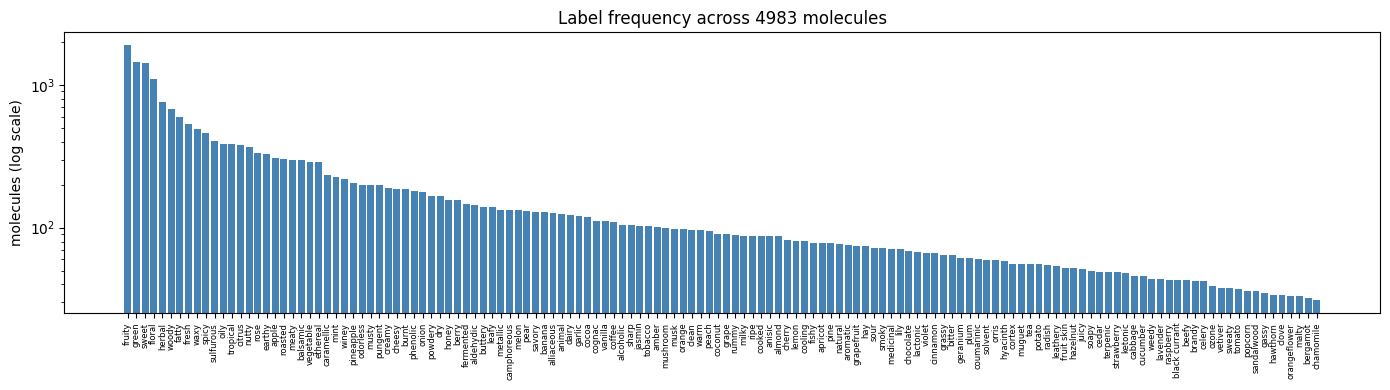

most common label:  fruity (1902 molecules)
rarest label:       chamomile (31 molecules)
labels with <100 positives: 76 of 138
labels with <50 positives:  26 of 138


In [3]:
freq = Y.sum(axis=0)
order = np.argsort(-freq)

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(np.arange(len(freq)), freq[order], color="steelblue")
ax.set_yscale("log")
ax.set_xticks(np.arange(len(freq)))
ax.set_xticklabels([label_names[i] for i in order], rotation=90, fontsize=6)
ax.set_ylabel("molecules (log scale)")
ax.set_title(f"Label frequency across {len(smiles)} molecules")
plt.tight_layout()
plt.show()

print(f"most common label:  {label_names[order[0]]} ({freq[order[0]]} molecules)")
print(f"rarest label:       {label_names[order[-1]]} ({freq[order[-1]]} molecules)")
print(f"labels with <100 positives: {int((freq < 100).sum())} of {len(label_names)}")
print(f"labels with <50 positives:  {int((freq < 50).sum())} of {len(label_names)}")

## Labels per molecule

Multi-label setting: each molecule carries several odor descriptors at once.

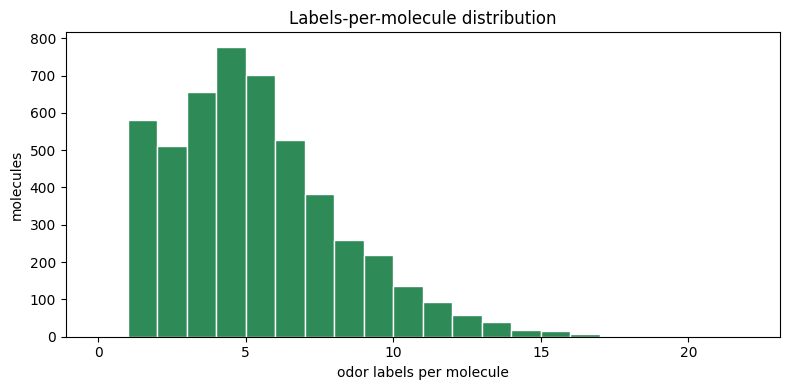

mean: 4.88, median: 4, max: 21
molecules with 0 labels: 0


In [4]:
lpm = Y.sum(axis=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lpm, bins=range(0, int(lpm.max()) + 2), color="seagreen", edgecolor="white")
ax.set_xlabel("odor labels per molecule")
ax.set_ylabel("molecules")
ax.set_title("Labels-per-molecule distribution")
plt.tight_layout()
plt.show()

print(f"mean: {lpm.mean():.2f}, median: {np.median(lpm):.0f}, max: {lpm.max()}")
print(f"molecules with 0 labels: {int((lpm == 0).sum())}")

## Molecular size and scaffold structure

Scaffold split context: acyclic molecules share the empty Murcko scaffold, which the split distributes randomly instead of grouping.

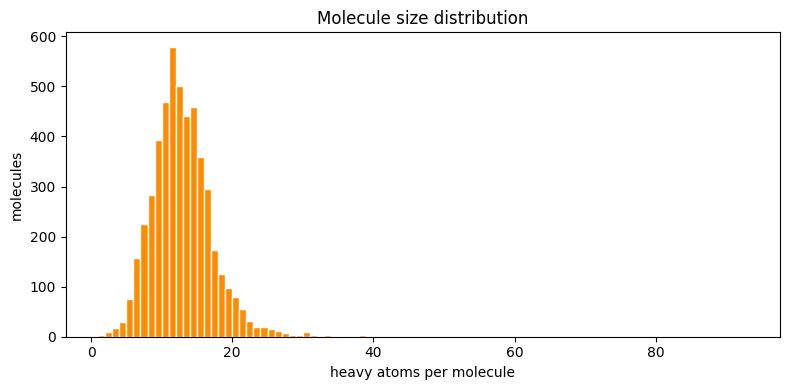

heavy atoms: mean 12.6, median 12, range 1-92
acyclic molecules: 2236 (44.9%)
unique non-empty scaffolds: 555


In [5]:
sizes = heavy_atom_counts(smiles)
scaffolds = [murcko_scaffold(s) for s in smiles]
acyclic = np.array([s == "" for s in scaffolds])

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(sizes, bins=range(int(sizes.min()), int(sizes.max()) + 2), color="darkorange", edgecolor="white")
ax.set_xlabel("heavy atoms per molecule")
ax.set_ylabel("molecules")
ax.set_title("Molecule size distribution")
plt.tight_layout()
plt.show()

print(f"heavy atoms: mean {sizes.mean():.1f}, median {np.median(sizes):.0f}, range {sizes.min()}-{sizes.max()}")
print(f"acyclic molecules: {acyclic.sum()} ({acyclic.mean():.1%})")
print(f"unique non-empty scaffolds: {len(set(scaffolds) - {''})}")

## Sample molecules with their labels

Legends show the raw `descriptors` text from the CSV.

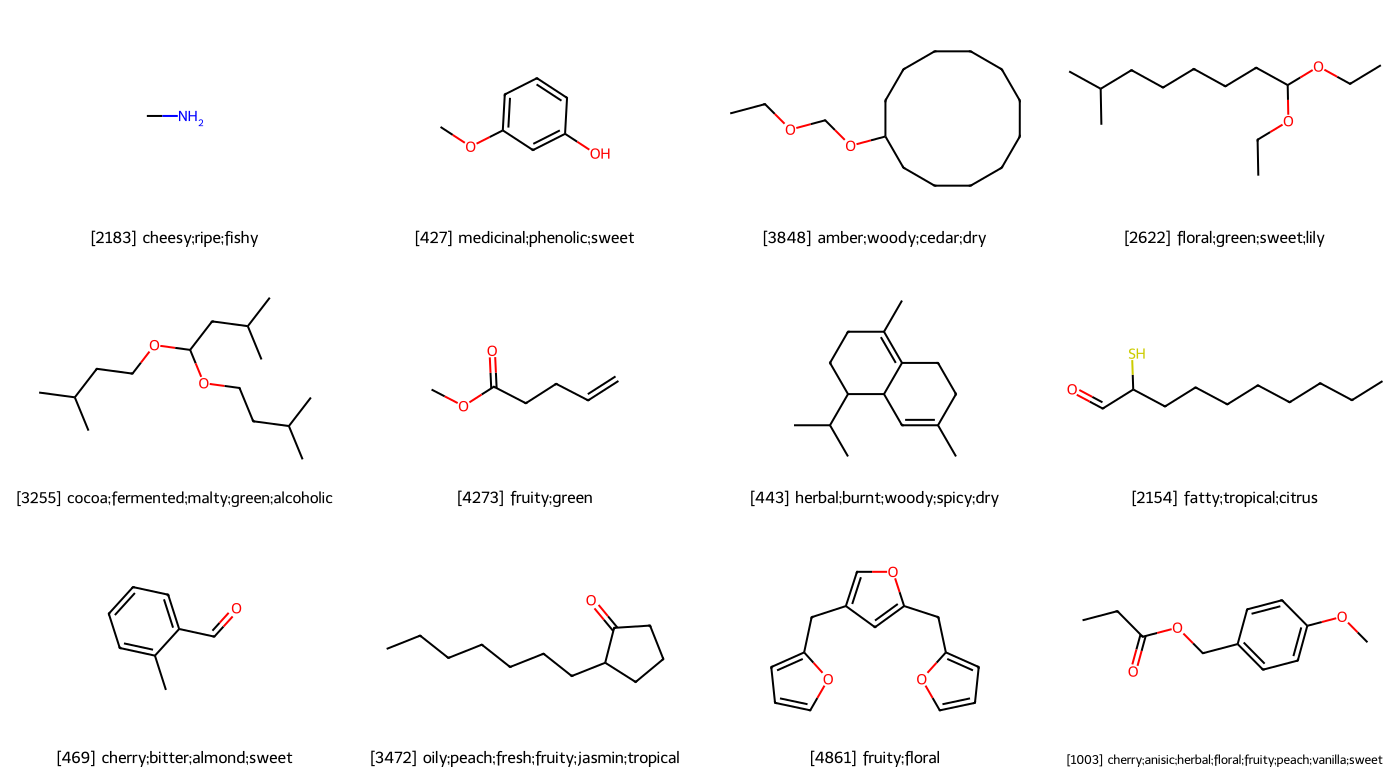

In [6]:
from rdkit.Chem import Draw

def truncate(text: str, n: int = 70) -> str:
    return text if len(text) <= n else text[: n - 3] + "..."

rng = np.random.default_rng(42)
pick = rng.choice(len(smiles), size=12, replace=False)
mols = [Chem.MolFromSmiles(smiles[i]) for i in pick]
legends = [f"[{i}] {truncate(descriptor_text[i])}" for i in pick]

Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(350, 260), legends=legends)

## Takeaways

1. **The label matrix is sparse and long-tailed.** Only **3.5%** of the 4983 x 138 cells
   are positive (24,312 total), and **76 of 138 labels have fewer than 100 positives**
   (rarest: *chamomile*, 31; most common: *fruity*, 1902). Macro-mean ROC-AUC alone would
   hide failures on rare labels, which is why every experiment also reports per-label
   metrics and mean PR-AUC, and why rare labels may end up single-class in the 10% test
   split and must be skipped safely.
2. **Odor is genuinely multi-label:** each molecule carries **4.88 labels on average**
   (median 4, max 21) and no molecule has zero labels — so a "one molecule = one scent"
   assumption would be wrong; models must rank several co-occurring descriptors.
3. **Molecules are small** (median 12 heavy atoms, range 1-92), which supports compact
   circular fingerprints (2048 bits) as a strong, cheap baseline input.
4. **44.9% of molecules are acyclic (2,236 of 4,983) and only 555 unique non-empty
   scaffolds** exist among the rest. A naive scaffold split would push the entire
   acyclic group (nearly half the dataset) into a single split; Aromacle instead assigns
   non-empty scaffold groups whole and scatters the empty-scaffold molecules randomly in
   80/10/10 proportions.